In [1]:
# === Imports ===
import pickle
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import sys

from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from scipy.stats import binned_statistic, median_abs_deviation
from scipy.interpolate import UnivariateSpline, LSQUnivariateSpline
from scipy.interpolate import interp1d

## Defining Functions

In [2]:
def gmi_diam_zang(color, i, d):
    '''
    Calculate stellar radii from g-i and i, based on Zang 2018
    https://ui.adsabs.harvard.edu/abs/2018PASP..130j4401Z/abstract
    ---
    color : (g-i) color for the stars
    i : i-band magnitude for the stars
    d : distance to the stars in kpc
    '''
    # log_theta = c0 + c1(X-Xp)
    X = color
    log_diam_0 = 0.920 + 0.316*(X-0.576)
    log_diam_g = log_diam_0 - 0.2*i
    stellar_diams = 10**log_diam_g # in mas
    
    # r = diam/2*w
    r_sol = 0.00465 # AU/R_sol
    w = 1/d # parallax, [mas]
    rads = stellar_diams/(2*w) # AU
    rads_sol = rads/r_sol # AU/(AU/R_sol) = AU*R_sol/AU = R_sol
    
    return stellar_diams, rads_sol

In [3]:
# === Isochrone Filter and Radii Calculation Function ===

'''
This function takes the name of your isochrone file and a log(age), filters the isochrone file for the appropriate 
    age, and calculates the stellar radii from the luminosity, temperature, etc.

The age of the bulge is another complicated question, but we've been using 10^10 years as the age. 
    So log(age) should just be 10.
'''
def load_iso(isofile,logages_):
    # these are just column numbers
    cRadius=0
    cMass=3
    cMini=2
    cMI=13
    cMTESS=-2
    cMGaia=-5
    cLum=6
    cTeff=4
    cAge=1
    logages = logages_
    
    # if you want multiple ages, give them as a list and this will keep all of them. Otherwise just give a single one.
    if isinstance(logages_,list):
        logages = np.array(logages_)
    elif not isinstance(logages_,np.ndarray):
        logages = np.array([logages])
    
    # Load isochrone, skipping rows that just have comments
    iso = pd.read_csv(isofile, sep='\\s+', header=None, skiprows=13, engine='python', comment='#')
                                                                                            
    #Replace the idx column with the radii                                                                  
    iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))
            
    # this does the actual filtering for the age(s) you want
    ret = []
    for i, logage in enumerate(logages):
        ret.append(iso[(iso.iloc[:,-1] <= 4.0) & (np.abs(iso.iloc[:,cAge]-logage)<0.001)])
    if len(ret)==1:
        ret = ret[0]
    
    return ret

## Loading in Files and Naming Columns 

In [4]:
# === Load in Pickle Files ===
pipedir = '/home/bernthold.17/SURP2025/'
rmz_gmi_spline_file = open(f"{pipedir}/Transforms/psrmz_psgmi_transform.pickle", 'rb')
rmz_imz_spline_file = open(f"{pipedir}/Transforms/psrmz_psimz_transform.pickle", 'rb')

rmz_gmi_spline = pickle.load(rmz_gmi_spline_file)
rmz_imz_spline = pickle.load(rmz_imz_spline_file)

rmz_gmi_spline_file.close()
rmz_imz_spline_file.close()

/tmp/slurmtmp.8855070/ipykernel_3627993/1832519988.py:6: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  rmz_gmi_spline = pickle.load(rmz_gmi_spline_file)
/tmp/slurmtmp.8855070/ipykernel_3627993/1832519988.py:7: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to acce

In [5]:
# === Load in MISHAPS File ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_N10.cmd.calibrate_ps"
contents = pd.read_csv(catalog_path, header = None, sep = '\\s+')

# === Apply Column Headers ===
column_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
contents.columns = column_labels

### Filter the Data

In [6]:
# === Apply Quality Filters ===
print(contents.shape)

mask_flags = (contents['qflag_i'] == 1) & (contents['qflag_g'] == 1) & (contents['qflag_r'] == 1) & (contents['qflag_z'] == 1)
# mask_err = (contents['mis_g_err'] < 0.2) & (contents['mis_i_err'] < 0.2) & (contents['mis_r_err'] < 0.2) & (contents['mis_z_err'] < 0.2)
# mask_sky = (contents["Sky_g"] < 25) & (contents["Sky_i"] < 170) & (contents["Sky_r"] < 800) & (contents["Sky_z"] < 3500)

# print(contents[['qflag_g', 'qflag_i', 'mis_g_err', 'mis_i_err', 'Sky_g', 'Sky_i']].describe(include='all'))

combined_mask = mask_flags #& mask_err & mask_sky
filtered_contents = contents[combined_mask]

print(filtered_contents.shape)

(127748, 56)
(11493, 56)


In [7]:
# === Load in PanSTARRS Isochrone File ===
isochrone_file = "/home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd"
print(f"Reading isochrone file from: {isochrone_file}")

logage = 10
isochrone = load_iso(isochrone_file, logage)

isochrone_file_columns = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
                          '[Fe/H]', 'PS_g', 'PS_r', 'PS_i', 'PS_z', 'PS_y', 'PS_w', 'PS_open', 'phase']
isochrone.columns = isochrone_file_columns

Reading isochrone file from: /home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd


/tmp/slurmtmp.8855070/ipykernel_3627993/1633689941.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0         1.449754
1         1.470619
2         1.510297
3         1.550594
4         1.591545
            ...   
105589    0.015550
105590    0.015499
105591    0.015449
105592    0.015401
105593    0.015353
Length: 105594, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))


## Convert from Absolute to Apparent Magnitude

In [8]:
d = 8000 # distance to the Bulge in parsecs, this will be needed for converting to apparent magnitude

ps1_iso_g = isochrone.loc[:,'PS_g'] + 5*np.log10(d) - 5
ps1_iso_r = isochrone.loc[:,'PS_r'] + 5*np.log10(d) - 5
ps1_iso_i = isochrone.loc[:,'PS_i'] + 5*np.log10(d) - 5
ps1_iso_z = isochrone.loc[:,'PS_z'] + 5*np.log10(d) - 5

#print(ps1_iso_g, ps1_iso_r, ps1_iso_i, ps1_iso_z)

## Using Extinction and Reddening Values from rcfit code to Estimate Stellar Radii

In [9]:
R_v = 3.1 # Ratio of total to selective extinction for the Milky Way, Rv = Av / E(B-V)
# fliter_lambda = [0.473, 0.642, 0.784, 0.926] # g, r, i, z, in microns from DECam

r_rc = 15.855734905524415
r = filtered_contents.loc[:, 'mis_r']

A_r = 0.7798146039198492

E_rmz = 0.34461858518480504

R_r = 2.2628338616783137

In [10]:
z_rc = 15.079085656946738
z = filtered_contents.loc[:, 'mis_z']

A_z = 0.41610270566272867

E_rmz_z = 0.34838788091343875

R_z = 1.1943661891215858

In [11]:
g_rc = 16.967472753476354
g = filtered_contents.loc[:, 'mis_g']

A_g = 1.1299591030708296

E_gmi = 0.45925969046657245

R_g = 2.4603925110929685

In [12]:
i_rc = 15.410868457783632
i = filtered_contents.loc[:, 'mis_i']

A_i = 0.5674468654068576

E_gmi_i = 0.4932267870613054
gmi = g - i

R_i = 1.1504786039455863

In [13]:
r_dred = r - A_r

z_dred = z - A_z

g_dred = g - A_g

i_dred = i - A_i

gmi_dred = gmi - E_gmi_i

print(f'Dereddening in the r-Band = {r_dred}, ' f'Dereddening in the z-Band= {z_dred},' 
      f'Dereddening in the g-Band= {g_dred}, ' f'Dereddening in the i-Band= {i_dred},'
      f'Dereddening of gmi = {gmi_dred}')

Dereddening in the r-Band = 254      17.198035
287      17.161275
300      18.010165
304      18.800685
307      17.234975
           ...    
99124    16.616505
99131    18.490495
99152    17.120295
99192    17.829235
99222    17.261695
Name: mis_r, Length: 11493, dtype: float64, Dereddening in the z-Band= 254      17.137377
287      17.083787
300      17.723307
304      18.678037
307      17.141527
           ...    
99124    16.268917
99131    18.389137
99152    17.120227
99192    17.666607
99222    17.042127
Name: mis_z, Length: 11493, dtype: float64,Dereddening in the g-Band= 254      17.568131
287      17.573421
300      18.394471
304      19.146661
307      17.644051
           ...    
99124    17.339831
99131    18.959641
99152    17.507251
99192    18.358881
99222    17.393881
Name: mis_g, Length: 11493, dtype: float64, Dereddening in the i-Band= 254      17.139963
287      17.097653
300      17.822583
304      18.718673
307      17.161873
           ...    
99124    16.447393


## Plot PanSTARRS Isochrone 

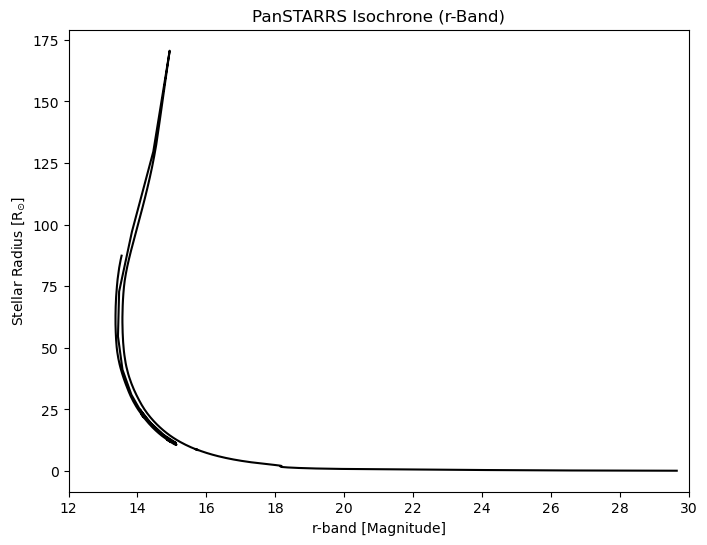

In [41]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(ps1_iso_r, isochrone.loc[:,'Radius_Estimate'], 'k-')

plt.xlim(12, 30)

plt.title('PanSTARRS Isochrone (r-Band)')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.show()

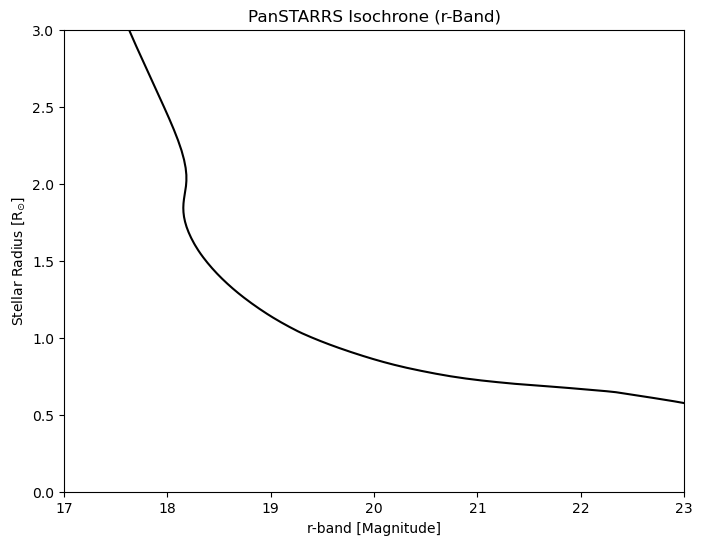

In [52]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(ps1_iso_r, ps1_iso_radius, 'k-')

plt.xlim(17.0, 23.0)
plt.ylim(0.0, 3.0)

plt.title('PanSTARRS Isochrone (r-Band)')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.show()

## Radius Estimates

In [16]:
# Based on magnitudes in isochrones (converted from absolute to apparent)
diameters, radius = gmi_diam_zang(gmi_dred, i_dred, 8.0) # dereddened gmi, dereddend i, distance of Galactic Bulge in kpc

### PanSTARRS Isochone

In [17]:
ps1_iso_diameters, ps1_iso_radius = gmi_diam_zang(ps1_iso_g - ps1_iso_i, ps1_iso_i, 8.0)

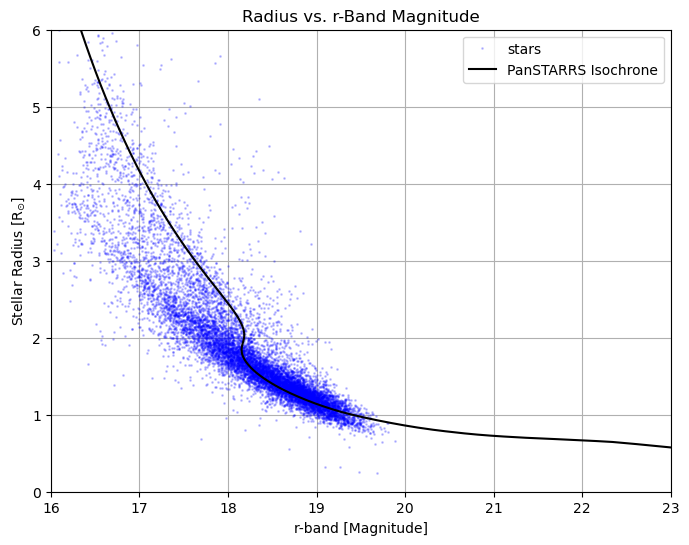

In [31]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(r_dred, radius, 'bo', ms = 1, label = 'stars', alpha = 0.2)
# plt.plot(ps1_iso_r, isochrone.loc[:,'Radius_Estimate'], 'k-')
plt.plot(ps1_iso_r, ps1_iso_radius, 'k-', ms = 2, label = 'PanSTARRS Isochrone', alpha = 1)

plt.xlim(16.0, 23.0)
plt.ylim(0.0, 6.0)

plt.title("Radius vs. r-Band Magnitude")
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.legend(loc = 'best')
plt.grid(True)
plt.show()

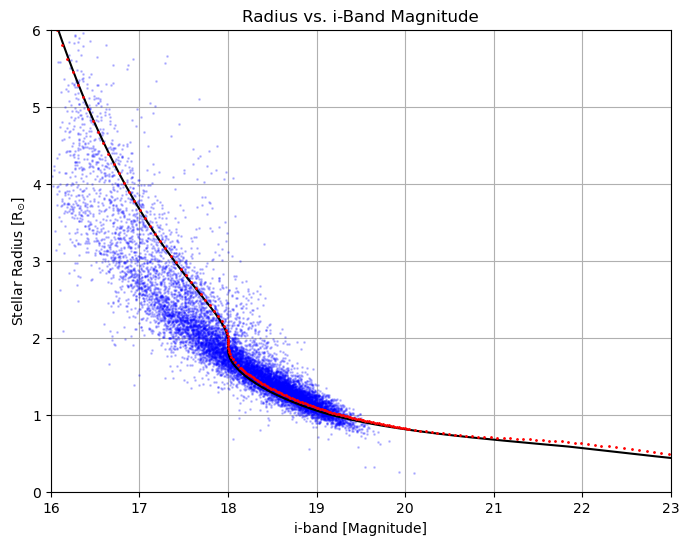

In [30]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(i_dred, radius, 'bo', ms = 1, alpha = 0.2)
plt.plot(ps1_iso_i, isochrone.loc[:,'Radius_Estimate'], 'k-')
plt.plot(ps1_iso_i, ps1_iso_radius, 'ro', ms = 1, alpha = 1)

plt.xlim(16.0, 23.0)
plt.ylim(0.0, 6.0)

plt.title("Radius vs. i-Band Magnitude")
plt.xlabel('i-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.grid(True)
plt.show()

### DECam Isochrone

In [20]:
# === Load in DECam Isochrone File ===
decam_isochrone_file = "/home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_DECam.iso.cmd"
print(f"Reading isochrone file from: {isochrone_file}")

logage = 10
decam_isochrone = load_iso(decam_isochrone_file, logage)

decam_isochrone_file_columns = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
            '[Fe/H]', 'DECam_u', 'DECam_g', 'DECam_r', 'DECam_i', 'DECam_z', 'DECam_Y', 'phase']
decam_isochrone.columns = decam_isochrone_file_columns

Reading isochrone file from: /home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd


/tmp/slurmtmp.8855070/ipykernel_3627993/1633689941.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0         1.449754
1         1.470619
2         1.510297
3         1.550594
4         1.591545
            ...   
105589    0.015550
105590    0.015499
105591    0.015449
105592    0.015401
105593    0.015353
Length: 105594, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))


In [38]:
decam_iso_g = decam_isochrone.loc[:,'DECam_g'] + 5*np.log10(d) - 5
decam_iso_r = decam_isochrone.loc[:,'DECam_r'] + 5*np.log10(d) - 5
decam_iso_i = decam_isochrone.loc[:,'DECam_i'] + 5*np.log10(d) - 5
decam_iso_z = decam_isochrone.loc[:,'DECam_z'] + 5*np.log10(d) - 5

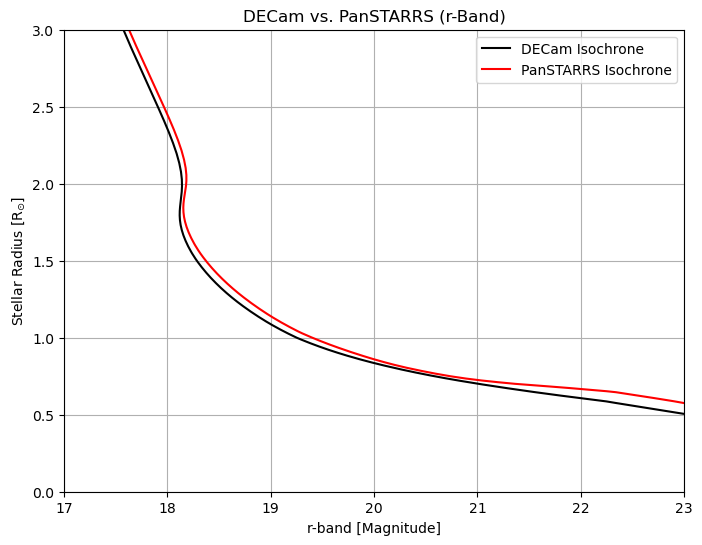

In [54]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(decam_iso_r, decam_isochrone.loc[:,'Radius_Estimate'], 'k-', label = 'DECam Isochrone')
plt.plot(ps1_iso_r, ps1_iso_radius, 'r-', label = 'PanSTARRS Isochrone')

plt.xlim(17.0, 23.0)
plt.ylim(0.0, 3.0)

plt.title('DECam vs. PanSTARRS (r-Band)')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.grid(True)
plt.legend(loc = 'best')

plt.show()

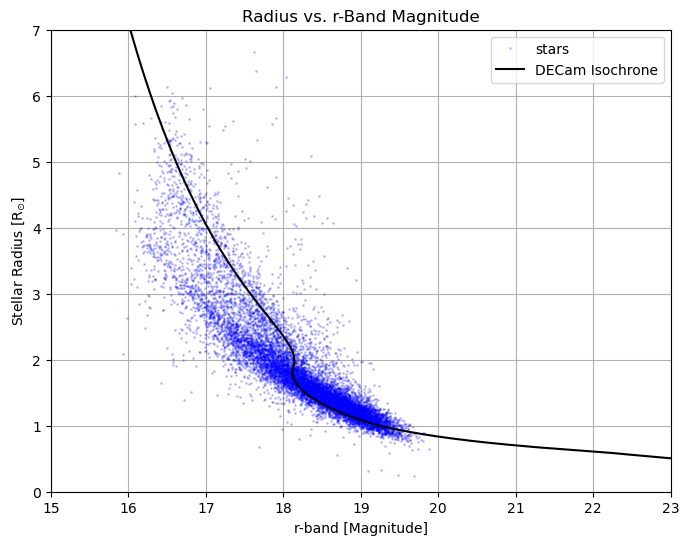

In [56]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(r_dred, radius, 'bo', ms = 1, label = 'stars', alpha = 0.2)
plt.plot(decam_iso_r, decam_isochrone.loc[:,'Radius_Estimate'], 'k-', label = 'DECam Isochrone')
#plt.plot(ps1_iso_r, ps1_iso_radius, 'r-', label = 'PanSTARRS Isochrone')

plt.xlim(15.0, 23.0)
plt.ylim(0.0, 7.0)

plt.title('Radius vs. r-Band Magnitude')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.grid(True)
plt.legend(loc = 'best')

plt.show()

### Residuals

In [26]:
# PanSTARRS
ps1_radius_interpolation = interp1d(ps1_iso_r, ps1_iso_radius)
ps1_radius_residual = (radius - ps1_radius_interpolation(r_dred))/radius

ps1_residual_vals, ps1_residual_edges, ps1_residual_bins = binned_statistic(r_dred,
                                                           ps1_radius_residual,
                                                           statistic = np.nanmedian,
                                                           bins = 25,
                                                           range=[16.0, 23.0]
                                                           )

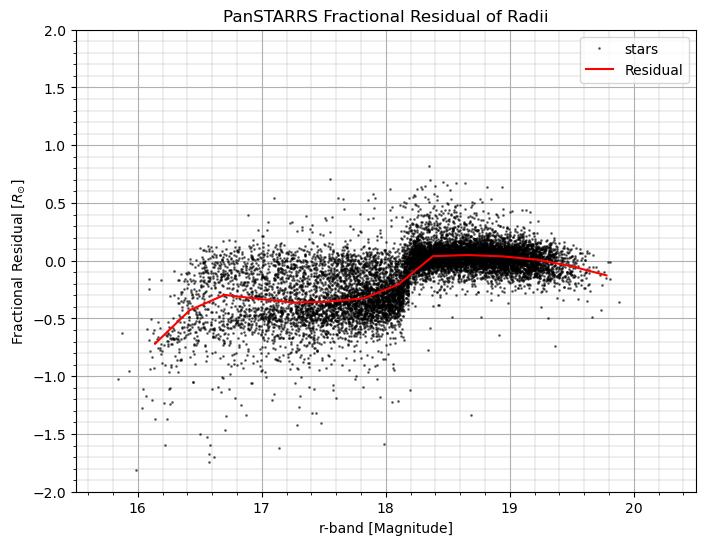

In [65]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(r_dred, ps1_radius_residual, 'ko', ms = 1, label = 'stars', alpha = 0.5)
plt.plot(0.5 * (ps1_residual_edges[:-1] + ps1_residual_edges[1:]), ps1_residual_vals, 'r-', label = 'Residual')
plt.title('PanSTARRS Fractional Residual of Radii')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Fractional Residual [$R_{\odot}$]')

plt.xlim(15.5, 20.5)
plt.ylim(-2, 2)

ax = plt.gca()
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

plt.grid(which='major')
plt.grid(which='minor', lw=0.3)

plt.legend(loc = 'best')
plt.show()

In [59]:
# DECam
decam_radius_interpolation = interp1d(decam_iso_r, decam_isochrone.loc[:,'Radius_Estimate'])
decam_radius_residual = (radius - decam_radius_interpolation(r_dred))/radius

decam_residual_vals, decam_residual_edges, decam_residual_bins = binned_statistic(r_dred,
                                                           decam_radius_residual,
                                                           statistic = np.nanmedian,
                                                           bins = 25,
                                                           range=[15.0, 23.0]
                                                           )

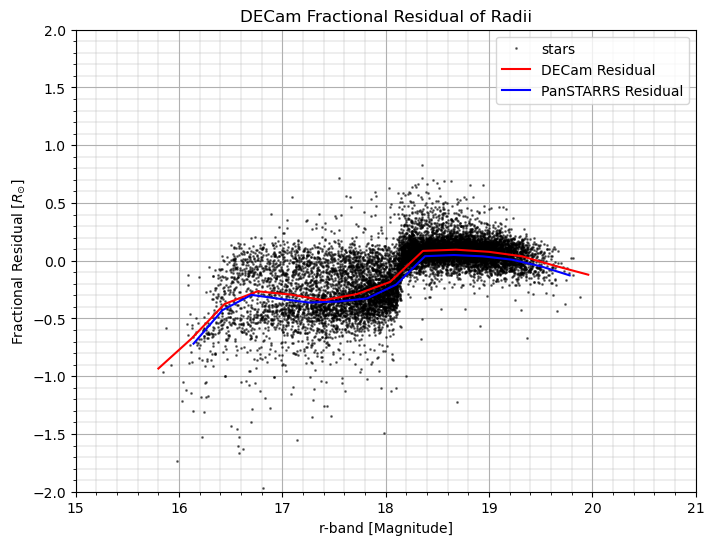

In [66]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(r_dred, decam_radius_residual, 'ko', ms = 1, label = 'stars', alpha = 0.5)
plt.plot(0.5 * (decam_residual_edges[:-1] + decam_residual_edges[1:]), decam_residual_vals, 'r-', label = 'DECam Residual')
plt.plot(0.5 * (ps1_residual_edges[:-1] + ps1_residual_edges[1:]), ps1_residual_vals, 'b-', label = 'PanSTARRS Residual')
plt.title('DECam Fractional Residual of Radii')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Fractional Residual [$R_{\odot}$]')

plt.xlim(15, 21)
plt.ylim(-2, 2)

ax = plt.gca()
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

plt.grid(which='major')
plt.grid(which='minor', lw=0.3)

plt.legend(loc = 'best')
plt.show()